In [3]:
import pandas as pd
import numpy as np
import shutil 
import os
import matplotlib.pyplot as plt

In [9]:
ls ../blast

alligator_proteins_db/           flanking_genes_vs_alligator.tsv


In [ ]:
flanking_genes_vs_alligator_cleaned.csv

In [33]:
df = pd.read_csv("../blast/flanking_genes_vs_alligator.tsv",sep="\t",names="qseqid sseqid pident length evalue bitscore".split()).sort_values(by="pident",ascending=False).reset_index(drop=True)
df.head(10)

,qseqid,sseqid,pident,length,evalue,bitscore
0,XP_065429982.1,ref|XP_059574666.1|,92.583,391,0.000000e+00,720.0
1,XP_065430705.1,ref|XP_059574124.1|,83.471,242,2.500000e-136,387.0
2,XP_065430705.1,ref|XP_059574803.1|,77.703,148,1.050000e-74,238.0
3,XP_065429985.1,ref|XP_059574144.1|,74.490,196,1.280000e-95,307.0
4,XP_065429986.1,ref|XP_059574144.1|,74.490,196,1.050000e-95,307.0
5,XP_065429972.1,ref|XP_059574654.1|,74.365,2715,0.000000e+00,3890.0
6,XP_065429989.1,ref|XP_059574144.1|,73.500,200,4.450000e-96,307.0
7,XP_065429990.1,ref|XP_059574144.1|,73.500,200,4.450000e-96,307.0
8,XP_065429988.1,ref|XP_059574144.1|,73.500,200,4.450000e-96,307.0
9,XP_065429972.1,ref|XP_059574653.1|,73.445,2749,0.000000e+00,3873.0


In [31]:
df.sseqid.unique()

<ArrowStringArray>
['ref|XP_059574666.1|', 'ref|XP_059574124.1|', 'ref|XP_059574803.1|',
 'ref|XP_059574144.1|', 'ref|XP_059574654.1|', 'ref|XP_059574653.1|',
 'ref|XP_059574091.1|', 'ref|XP_059583281.1|', 'ref|XP_059583273.1|',
 'ref|XP_059583279.1|',
 ...
 'ref|XP_019335282.1|', 'ref|XP_014452232.1|', 'ref|XP_059570237.1|',
 'ref|XP_006265667.1|', 'ref|XP_006273328.2|', 'ref|XP_019337748.1|',
 'ref|XP_019337747.1|', 'ref|XP_014461281.2|', 'ref|XP_014458254.2|',
 'ref|XP_059587032.1|']
Length: 822, dtype: str

In [53]:
sum(df.pident > 60)/df.shape[0]

0.008114939470533458

    ~183 percents are over 60 --> will take top 200

In [62]:
top_df = df.iloc[:200]
print(top_df.shape)
top_df.head(5)

(200, 6)


,qseqid,sseqid,pident,length,evalue,bitscore
0,XP_065429982.1,ref|XP_059574666.1|,92.583,391,0.000000e+00,720.0
1,XP_065430705.1,ref|XP_059574124.1|,83.471,242,2.500000e-136,387.0
2,XP_065430705.1,ref|XP_059574803.1|,77.703,148,1.050000e-74,238.0
3,XP_065429985.1,ref|XP_059574144.1|,74.490,196,1.280000e-95,307.0
4,XP_065429986.1,ref|XP_059574144.1|,74.490,196,1.050000e-95,307.0


In [68]:
top_df["sseqid_alt"] = top_df.sseqid.apply( lambda x: x[4:-1] )

top_df

,qseqid,sseqid,pident,length,evalue,bitscore,sseqid_alt
0,XP_065429982.1,ref|XP_059574666.1|,92.583,391,0.000000e+00,720.0,XP_059574666.1
1,XP_065430705.1,ref|XP_059574124.1|,83.471,242,2.500000e-136,387.0,XP_059574124.1
2,XP_065430705.1,ref|XP_059574803.1|,77.703,148,1.050000e-74,238.0,XP_059574803.1
3,XP_065429985.1,ref|XP_059574144.1|,74.490,196,1.280000e-95,307.0,XP_059574144.1
4,XP_065429986.1,ref|XP_059574144.1|,74.490,196,1.050000e-95,307.0,XP_059574144.1
...,...,...,...,...,...,...,...
195,XP_042703928.2,ref|XP_059577195.1|,60.000,255,1.610000e-96,318.0,XP_059577195.1
196,XP_065429976.1,ref|XP_059577195.1|,60.000,255,2.290000e-96,318.0,XP_059577195.1
197,XP_065429979.1,ref|XP_059583281.1|,59.912,227,7.750000e-81,282.0,XP_059583281.1
198,XP_065429979.1,ref|XP_059583273.1|,59.912,227,6.890000e-81,282.0,XP_059583273.1


In [64]:
pwd

'/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/notes'

In [76]:
top_df.sseqid_alt.to_csv("../blast/alligator_tophits.csv",header=False,index=False)

---

In [92]:
hits = pd.read_csv("../alligator_coordinates.tsv",sep="\t")
hits.head()

,protein_accession,chromosome,feature,start,end,strand,attributes
0,XP_006258022.1,NC_081839.1,CDS,24270298,24270827,+,ID=cds-XP_006258022.1;Parent=rna-XM_006257960....
1,XP_006258024.1,NC_081839.1,CDS,24270298,24270827,+,ID=cds-XP_006258024.1;Parent=rna-XM_006257962....
2,XP_006269472.1,NC_081824.1,CDS,295961345,295961865,-,ID=cds-XP_006269472.1;Parent=rna-XM_006269410....
3,XP_006269473.1,NC_081824.1,CDS,295961345,295961865,-,ID=cds-XP_006269473.1;Parent=rna-XM_006269411....
4,XP_006272420.1,NC_081834.1,CDS,51387310,51388343,+,ID=cds-XP_006272420.1;Parent=rna-XM_006272358....


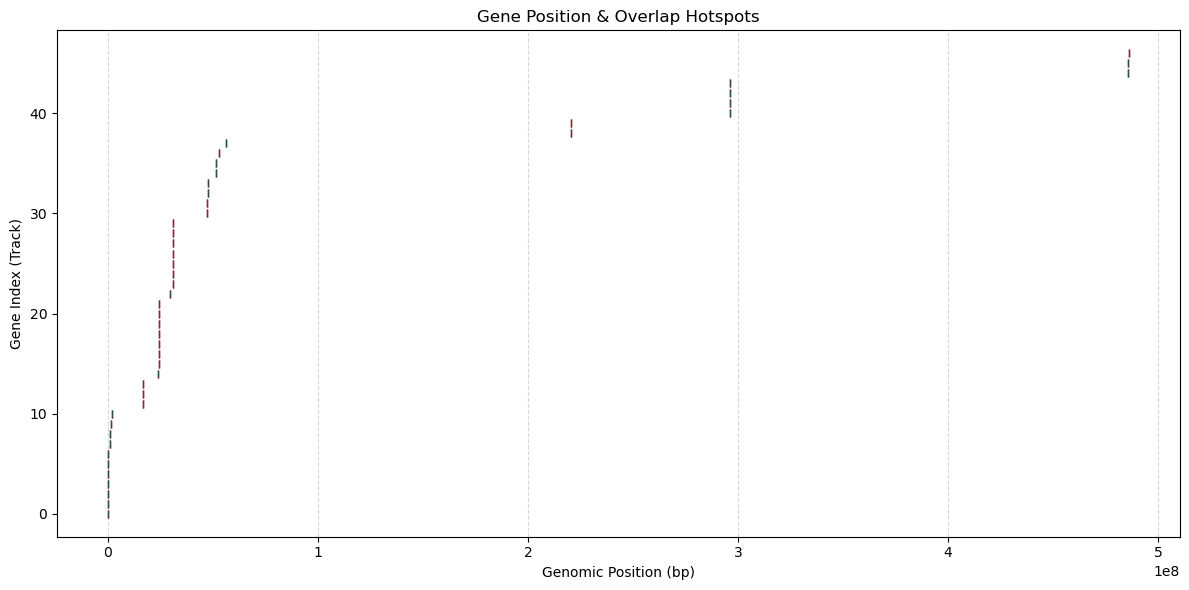

In [136]:
hits = hits.sort_values('start').reset_index(drop=True)

# 2. Plot
plt.figure(figsize=(12, 6))

# plt.hlines draws horizontal lines: y-position, start (xmin), stop (xmax)
plt.hlines(y=hits.index, xmin=hits['start'], xmax=hits['end'], color='teal', linewidth=1e10)

# Optional: Add dots at start and stop coordinates
plt.plot(hits['start'], hits.index, '|', color='red', markersize=6)
plt.plot(hits['end'], hits.index, '|', color='darkslategray', markersize=6)

plt.xlabel('Genomic Position (bp)')
plt.ylabel('Gene Index (Track)')
plt.title('Gene Position & Overlap Hotspots')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
#plt.xlim(-0.03e8,0.7e8)

plt.tight_layout()
plt.show()

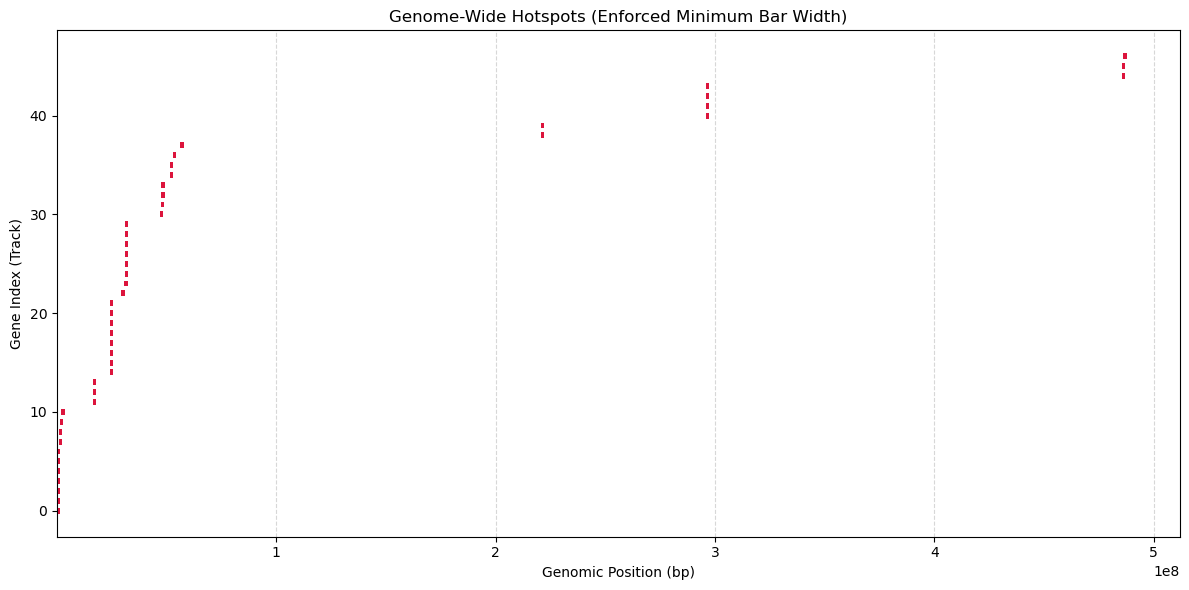

In [120]:
import numpy as np
import matplotlib.pyplot as plt

hits_sorted = hits.sort_values('start').reset_index(drop=True)

# Calculate real length, but enforce a minimum display length (e.g., 1.5 Mb) so it renders visibly
min_display_width = 1.5e6 
hits_sorted['length'] = np.maximum(hits_sorted['end'] - hits_sorted['start'], min_display_width)

plt.figure(figsize=(12, 6))

# plt.barh: y=index, width=span, left=start_position
plt.barh(y=hits_sorted.index, width=hits_sorted['length'], left=hits_sorted['start'], color='crimson', height=0.6)

plt.xlabel('Genomic Position (bp)')
plt.ylabel('Gene Index (Track)')
plt.title('Genome-Wide Hotspots (Enforced Minimum Bar Width)')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [128]:
hits

,protein_accession,chromosome,feature,start,end,strand,attributes
0,XP_059583281.1,NC_081824.1,CDS,92589,94558,+,ID=cds-XP_059583281.1;Parent=rna-XM_059727298....
1,XP_059583276.1,NC_081824.1,CDS,92589,94558,+,ID=cds-XP_059583276.1;Parent=rna-XM_059727293....
2,XP_059583273.1,NC_081824.1,CDS,92589,94558,+,ID=cds-XP_059583273.1;Parent=rna-XM_059727290....
3,XP_059583272.1,NC_081824.1,CDS,92589,94558,+,ID=cds-XP_059583272.1;Parent=rna-XM_059727289....
4,XP_059583268.1,NC_081824.1,CDS,92589,94558,+,ID=cds-XP_059583268.1;Parent=rna-XM_059727285....
5,XP_019345540.1,NC_081824.1,CDS,92589,94558,+,ID=cds-XP_019345540.1;Parent=rna-XM_019489995....
6,XP_059583279.1,NC_081824.1,CDS,92589,94558,+,ID=cds-XP_059583279.1;Parent=rna-XM_059727296....
7,XP_014452109.2,NC_081830.1,CDS,860232,861202,-,ID=cds-XP_014452109.2;Parent=rna-XM_014596623....
8,XP_059577268.1,NC_081825.1,CDS,1081761,1083491,-,ID=cds-XP_059577268.1;Parent=rna-XM_059721285....
9,XP_059577195.1,NC_081825.1,CDS,1470074,1471606,+,ID=cds-XP_059577195.1;Parent=rna-XM_059721212....


In [134]:
hits[ hits.start < 1e8 ].protein_accession.unique()

<ArrowStringArray>
['XP_059583281.1', 'XP_059583276.1', 'XP_059583273.1', 'XP_059583272.1',
 'XP_059583268.1', 'XP_019345540.1', 'XP_059583279.1', 'XP_014452109.2',
 'XP_059577268.1', 'XP_059577195.1', 'XP_059577151.1', 'XP_059574263.1',
 'XP_006275935.2', 'XP_059574264.1', 'XP_059573815.1', 'XP_006258022.1',
 'XP_006258024.1', 'XP_014456383.1', 'XP_019345644.1', 'XP_019345645.1',
 'XP_019345646.2', 'XP_059575637.1', 'XP_059574091.1', 'XP_059574803.1',
 'XP_059574124.1', 'XP_059574144.1', 'XP_006277782.4', 'XP_059574666.1',
 'XP_059574653.1', 'XP_059574654.1', 'XP_059570223.1', 'XP_059570229.1',
 'XP_019331482.1', 'XP_059571419.1', 'XP_006272420.1', 'XP_006272421.1',
 'XP_059570243.1', 'XP_059571117.1']
Length: 38, dtype: str

In [142]:
top_df.head()

,qseqid,sseqid,pident,length,evalue,bitscore,sseqid_alt
0,XP_065429982.1,ref|XP_059574666.1|,92.583,391,0.000000e+00,720.0,XP_059574666.1
1,XP_065430705.1,ref|XP_059574124.1|,83.471,242,2.500000e-136,387.0,XP_059574124.1
2,XP_065430705.1,ref|XP_059574803.1|,77.703,148,1.050000e-74,238.0,XP_059574803.1
3,XP_065429985.1,ref|XP_059574144.1|,74.490,196,1.280000e-95,307.0,XP_059574144.1
4,XP_065429986.1,ref|XP_059574144.1|,74.490,196,1.050000e-95,307.0,XP_059574144.1


In [144]:
merged = top_df.merge(
    hits,
    left_on="sseqid_alt",
    right_on="protein_accession",
    how="left"
)

merged.head()

,qseqid,sseqid,pident,length,evalue,bitscore,sseqid_alt,protein_accession,chromosome,feature,start,end,strand,attributes
0,XP_065429982.1,ref|XP_059574666.1|,92.583,391,0.000000e+00,720.0,XP_059574666.1,XP_059574666.1,NC_081838.1,CDS,30970907,30971119,+,ID=cds-XP_059574666.1;Parent=rna-XM_059718683....
1,XP_065430705.1,ref|XP_059574124.1|,83.471,242,2.500000e-136,387.0,XP_059574124.1,XP_059574124.1,NC_081838.1,CDS,30944068,30944088,+,ID=cds-XP_059574124.1;Parent=rna-XM_059718141....
2,XP_065430705.1,ref|XP_059574803.1|,77.703,148,1.050000e-74,238.0,XP_059574803.1,XP_059574803.1,NC_081838.1,CDS,30777728,30778782,-,ID=cds-XP_059574803.1;Parent=rna-XM_059718820....
3,XP_065429985.1,ref|XP_059574144.1|,74.490,196,1.280000e-95,307.0,XP_059574144.1,XP_059574144.1,NC_081838.1,CDS,30946331,30946364,-,ID=cds-XP_059574144.1;Parent=rna-XM_059718161....
4,XP_065429986.1,ref|XP_059574144.1|,74.490,196,1.050000e-95,307.0,XP_059574144.1,XP_059574144.1,NC_081838.1,CDS,30946331,30946364,-,ID=cds-XP_059574144.1;Parent=rna-XM_059718161....


In [146]:
pwd

'/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/notes'

In [150]:
merged.to_csv("../blast/blast_gator_coords.csv",index=False)

In [168]:
merged_sorted = merged.sort_values(
    ["chromosome", "start"]
)

print(
    merged_sorted[
        [
            "qseqid",
            "sseqid_alt",
            "pident",
            "length",
            "bitscore",
            "chromosome",
            "start",
            "end",
            "strand"
        ]
    ].head(20)
)

            qseqid      sseqid_alt  pident  length  bitscore   chromosome  \
11  XP_065429976.1  XP_059583281.1  62.637     273     356.0  NC_081824.1   
12  XP_065429978.1  XP_059583273.1  62.637     273     356.0  NC_081824.1   
13  XP_042703928.2  XP_059583279.1  62.637     273     355.0  NC_081824.1   
14  XP_065429978.1  XP_019345540.1  62.637     273     355.0  NC_081824.1   
15  XP_065429978.1  XP_059583279.1  62.637     273     355.0  NC_081824.1   
16  XP_065429981.1  XP_059583276.1  62.637     273     354.0  NC_081824.1   
17  XP_042703928.2  XP_019345540.1  62.637     273     355.0  NC_081824.1   
18  XP_065429976.1  XP_059583279.1  62.637     273     356.0  NC_081824.1   
19  XP_065429978.1  XP_059583276.1  62.637     273     355.0  NC_081824.1   
20  XP_042703928.2  XP_059583268.1  62.637     273     355.0  NC_081824.1   
21  XP_065429976.1  XP_059583272.1  62.637     273     356.0  NC_081824.1   
22  XP_065429976.1  XP_059583268.1  62.637     273     355.0  NC_081824.1   

In [162]:
merged.chromosome.value_counts()

chromosome
NC_081824.1    78
NC_081834.1    42
NC_081838.1    22
NC_081825.1    22
NC_081835.1    14
NC_081828.1     8
NC_081830.1     7
NC_081839.1     7
Name: count, dtype: int64

---
---


In [181]:
import pandas as pd

def parse_attrs(s):
    return dict(kv.split("=", 1) for kv in s.split(";") if "=" in kv)

def load_gff(path):
    genes, cds = [], []
    with open(path) as f:
        for line in f:
            if line.startswith("#"): continue
            c = line.rstrip("\n").split("\t")
            if len(c) < 9: continue
            a = parse_attrs(c[8])
            geneid = next((x.split(":")[1] for x in a.get("Dbxref", "").split(",")
                           if x.startswith("GeneID")), None)
            if c[2] in ("gene", "pseudogene"):
                genes.append(dict(geneid=geneid, symbol=a.get("Name"), chrom=c[0],
                                  start=int(c[3]), end=int(c[4]), strand=c[6]))
            elif c[2] == "CDS":
                cds.append(dict(protein=a.get("protein_id"), geneid=geneid))
    genes = pd.DataFrame(genes).drop_duplicates("geneid")
    cds = pd.DataFrame(cds).drop_duplicates()
    # gene order along each chromosome (this is what synteny actually uses)
    genes = genes.sort_values(["chrom", "start"])
    genes["order"] = genes.groupby("chrom").cumcount()
    return genes, cds

turtle_genes, turtle_cds = load_gff("../turtle/genome/ncbi_dataset/data/GCF_011386835.1/genomic.gff")
gator_genes, gator_cds = load_gff("../alligator/genome/gator_GCF_030867095.1_copy.gff")

In [182]:
p = turtle_genes[turtle_genes.symbol == "PRDM9"].iloc[0]
hood = turtle_genes[(turtle_genes.chrom == p.chrom) &
                    (turtle_genes.order.between(p.order - 10, p.order + 10))]

In [185]:
blast = merged.merge(turtle_cds.rename(columns={"protein": "qseqid", "geneid": "q_gene"}), on="qseqid")
blast = blast.merge(gator_cds.rename(columns={"protein": "sseqid_alt", "geneid": "s_gene"}), on="sseqid_alt")

best = (blast.sort_values("bitscore", ascending=False)
             .drop_duplicates(["q_gene", "s_gene"]))          # one row per gene pair
best = best.merge(turtle_genes[["geneid","symbol","order"]].add_prefix("t_"),
                  left_on="q_gene", right_on="t_geneid")
best = best.merge(gator_genes[["geneid","symbol","chrom","order"]].add_prefix("a_"),
                  left_on="s_gene", right_on="a_geneid")

In [214]:
# 1. Do the flanking genes land on the same alligator chromosome?
top = best.sort_values("bitscore", ascending=False).drop_duplicates("q_gene")
print(top.groupby("a_chrom").size())

# 2. Within that chromosome, are they close together and in a similar order?
print(top[top.a_chrom == "NC_081838.1"].sort_values("a_order")[["t_symbol","t_order","a_symbol","a_order"]])

a_chrom
NC_081828.1    1
NC_081838.1    5
dtype: int64
        t_symbol  t_order      a_symbol  a_order
3           ERFL       44          ERFL     2133
17       ARHGEF1       43       ARHGEF1     2134
1   LOC101947105       39  LOC102572676     2138
2        TMEM145       38       TMEM145     2139
0          MEGF8       33         MEGF8     2140


*PRDM9 happens between LOC... & ARHG...*

In [207]:
! cut -d, -f1 ../notes/turtle_genes_loci.csv | head -n 10

TURTLE PRDM9 LOCUS
name
MEGF8
TMEM145
LOC101947105
PRDM9
CD79A
ARHGEF1
ERFL


In [216]:
print(top[top.a_chrom == "NC_081828.1"].sort_values("a_order")[["t_symbol","t_order","a_symbol","a_order"]])

  t_symbol  t_order      a_symbol  a_order
4    PRDM9       41  LOC102573831     2154


^^PRDM9 match but is a ["zinc finger" match](https://www.ncbi.nlm.nih.gov/datasets/gene/102573831/)

Text(0, 0.5, 'alligator gene order')

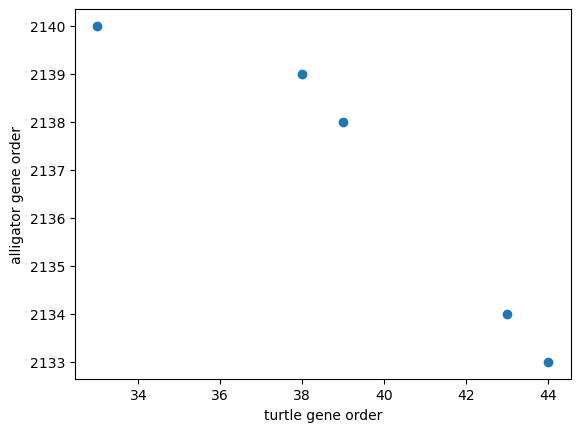

In [193]:
import matplotlib.pyplot as plt
sub = top[top.a_chrom == "NC_081838.1"]
plt.scatter(sub.t_order, sub.a_order); plt.xlabel("turtle gene order"); plt.ylabel("alligator gene order")

    reversed¿

---
---
### BLAST results on turtle gene vs isolated gator chromosome
---
---

In [261]:
! pwd

/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/notes


In [263]:
! ls ../blast

alligator_NC_081838.1_db
alligator_proteins_db
alligator_tophits.csv
blast_gator_coords.csv
dc-megablast_turtle_prdm9_gene_vs_gator_NC_081838.1.tabular
find_alligator_coords.py
flanking_genes_vs_alligator.tsv


In [279]:
chrom15 = pd.read_csv("../blast/dc-megablast_turtle_prdm9_gene_vs_gator_NC_081838.1.tabular",sep="\t",
           names = """qseqid
sseqid
pident
length
mismatch
gapopen
qstart
qend
sstart
send
evalue
bitscore""".split()).sort_values(by="pident",ascending=False).reset_index(drop=True)

chrom15.head(5)

,qseqid,sseqid,pident,length,mismatch,gapopen,astart,gend,sstart,send,evalue,bitscore
0,NC_088810.1:992989-1017260,NC_081838.1,75.926,162,36,2,22726,22885,27624337,27624177,2.950000e-22,111.0
1,NC_088810.1:992989-1017260,NC_081838.1,73.913,345,90,0,22699,23043,5361059,5361403,2.760000e-54,217.0
2,NC_088810.1:992989-1017260,NC_081838.1,73.780,164,41,2,22668,22830,27441476,27441314,2.270000e-17,96.0
3,NC_088810.1:992989-1017260,NC_081838.1,73.563,261,67,2,23161,23420,24077184,24076925,9.650000e-35,153.0
4,NC_088810.1:992989-1017260,NC_081838.1,73.519,287,70,4,22983,23266,24021887,24021604,5.340000e-38,163.0


**rerun above blast but with isolated genes highlighted as specifically flanking prdm9**

awk output for coords that bound between LOC... & ARHG...:
```
NC_081838.1	Gnomon	gene	30944399	30948963	.	-	ID=gene-ARHGEF1;Dbxref=GeneID:106737254;Name=ARHGEF1;description=Rho guanine nucleotide exchange factor 1;gbkey=Gene;gene=ARHGEF1;gene_biotype=protein_coding
NC_081838.1	Gnomon	gene	30960558	30963977	.	-	ID=gene-LOC102572676;Dbxref=GeneID:102572676;Name=LOC102572676;description=toll-like receptor 13;gbkey=Gene;gene=LOC102572676;gene_biotype=protein_coding
```

****both minus strand***

In [283]:
coords = (30944399,30963977) # assuming numbers are chromsome-indexing and not genome-indexing

In [285]:
coords[1]-coords[0]

19578

In [291]:
pwd

'/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/notes'

In [299]:
!pip install biopython
from Bio import SeqIO

# Load the chromosome FASTA file
chromosome_file = "../alligator/genome/gator_NC_081838.1.fasta"
record = SeqIO.read(chromosome_file, "fasta")

# Define your coordinates (0-indexed for Python slicing, so subtract 1 from start)
start_pos = coords[0] - 1
end_pos = coords[1]

# Slice the sequence
extracted_seq = record.seq[start_pos:end_pos]

# Save to a new FASTA file
output_record = record[start_pos:end_pos]
output_record.id = f"{record.id}_LOC102572676_to_ARHGEF1"
output_record.description = (
    f"Extracted region from {start_pos + 1} to {end_pos}"
)

with open("../regions/gator/LOC_to_ARHG.fa", "w") as output_handle:
    SeqIO.write(output_record, output_handle, "fasta")

print(
    f"Successfully extracted {len(extracted_seq):,} bp to 'LOC_to_ARHG.fa'"
)

Successfully extracted 19,579 bp to 'LOC_to_ARHG.fa'


---
---
#### try blastp
---
---

In [315]:
# convert to protein 
from Bio import SeqIO
from Bio.Seq import Seq
with open('/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/alligator/genome/gator_NC_081838.1_protein.fasta', 'w') as out:
    for record in SeqIO.parse('/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/alligator/genome/gator_NC_081838.1.fasta', 'fasta'):
        remainder = len(record.seq) % 3
        seq = record.seq + ('N' * (3 - remainder)) if remainder != 0 else record.seq
        prot = seq.translate()
        out.write(f'>{record.id}\n{prot}\n')

In [317]:
# convert to protein 
with open('/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/regions/gator/LOC_to_ARHG_protein.fa', 'w') as out:
    for record in SeqIO.parse('/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/regions/gator/LOC_to_ARHG.fa', 'fasta'):
        remainder = len(record.seq) % 3
        seq = record.seq + ('N' * (3 - remainder)) if remainder != 0 else record.seq
        prot = seq.translate()
        out.write(f'>{record.id}\n{prot}\n')

In [319]:
# convert to protein 
with open('/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/turtle/prdm9/ncbi_dataset/data/gene_protein.fna', 'w') as out:
    for record in SeqIO.parse('/Users/zainabsiddiqui/Downloads/Crocs/Data/synteny/turtle/prdm9/ncbi_dataset/data/gene.fna', 'fasta'):
        remainder = len(record.seq) % 3
        seq = record.seq + ('N' * (3 - remainder)) if remainder != 0 else record.seq
        prot = seq.translate()
        out.write(f'>{record.id}\n{prot}\n')

## tblastx results

```
tblastx \
    -query turtle/prdm9/ncbi_dataset/data/gene.fna \
    -db blast/alligator_LOCtoARHG_db/alligator_LOCtoARHG_db \
    -evalue 1e-3  \
    -outfmt 6 \
    -out blast/alligator_LOCtoARHG_db/LOCtoARHG_blastx_hits.csv
```

In [373]:
tblastx_hits = pd.read_csv("../blast/alligator_LOCtoARHG_db/LOCtoARHG_blastx_hits.csv",
           sep="\t",
           names="qseqid   sseqid  pident  length  mismatch        gapopen qstart   qend    sstart  send    evalue      bitscore".split()
                          ).sort_values(by="pident",ascending=False).reset_index(drop=True)
print(tblastx_hits.shape)
tblastx_hits.head()

(151, 12)


,qseqid,sseqid,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore
0,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,87.500,8,1,0,123,146,14473,14450,2.170000e-36,22.1
1,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,87.500,8,1,0,22980,22957,3134,3157,5.540000e-14,21.7
2,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,83.333,12,2,0,13444,13409,11199,11234,8.740000e-33,24.9
3,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,76.471,17,4,0,13770,13820,11006,10956,2.170000e-36,36.8
4,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,75.000,8,2,0,22899,22922,8819,8796,3.910000e-18,22.6


In [365]:
tblastx_hits.qseqid.unique()

<ArrowStringArray>
['NC_088810.1:992989-1017260']
Length: 1, dtype: str

In [355]:
tblastx_hits.sstart.min()

220

In [375]:
tblastx_hits.send.max()

19459

In [371]:
tblastx_hits[tblastx_hits.qend == tblastx_hits.qend.max()]

,qseqid,sseqid,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore
143,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,30.435,46,32,0,23963,24100,4434,4297,0.000261,26.7


In [377]:
tblastx_hits.qstart.min(), tblastx_hits.qend.max()

(123, 24100)

In [381]:
tblastx_hits.head(20)

,qseqid,sseqid,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore
0,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,87.500,8,1,0,123,146,14473,14450,2.170000e-36,22.1
1,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,87.500,8,1,0,22980,22957,3134,3157,5.540000e-14,21.7
2,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,83.333,12,2,0,13444,13409,11199,11234,8.740000e-33,24.9
3,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,76.471,17,4,0,13770,13820,11006,10956,2.170000e-36,36.8
4,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,75.000,8,2,0,22899,22922,8819,8796,3.910000e-18,22.6
5,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,72.727,11,3,0,357,389,14265,14233,4.600000e-10,23.5
6,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,72.222,18,5,0,13822,13769,10954,11007,8.740000e-33,31.3
7,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,71.429,14,4,0,2970,3011,13098,13057,3.910000e-18,22.6
8,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,70.000,10,3,0,14262,14233,12473,12502,2.010000e-07,22.6
9,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,70.000,10,3,0,2094,2065,15675,15704,5.540000e-14,22.1


    ^^ questionable if any hits are significant (short & low pident)

### tiberius output

In [387]:
pd.read_csv("../blast/tiberius_g2_db/tiberiusg2_tblastx.csv",
           sep="\t",
           names="qseqid   sseqid  pident  length  mismatch        gapopen qstart   qend    sstart  send    evalue      bitscore".split()
                          ).sort_values(by="pident",ascending=False).reset_index(drop=True)

,qseqid,sseqid,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore
0,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,70.000,10,3,0,14399,14370,218,247,0.000343,22.6
1,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,70.000,10,3,0,2094,2065,764,793,0.000343,22.1
2,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,50.000,22,11,0,651,586,973,1038,0.000343,24.4
3,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,34.286,35,23,0,506,402,1024,1128,0.000343,24.9
4,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,33.333,33,22,0,8554,8456,254,352,0.000343,26.3
5,NC_088810.1:992989-1017260,NC_081838.1_LOC102572676_to_ARHGEF1,28.125,32,23,0,5572,5477,372,467,0.000343,22.6


    ^^ again, questionable hits